Тест базовых функций:
Ping: True
Now: 20261019T17:59:01
Type: ['2', "<class 'int'>", 2]
Sum: 5
Pow: 8

Проверка чёрного списка:
('Иванов', 'Иван', 'Иванович', '22.03.1989') => Иванов Иван Иванович 22.03.1989 : yes
('иванов', 'иван', 'иванович', '22.03.1989') => иванов иван иванович 22.03.1989 : yes
('Иваноа', 'Иван', 'Иванович', '22.03.1989') => ['Иванов Иван Иванович 22.03.1989', 'similar']
('Сидоров', 'Пётр', 'Петрович', '01.01.1990') => Сидоров Пётр Петрович 01.01.1990 : no

Обработка изображений:
Инверсия:


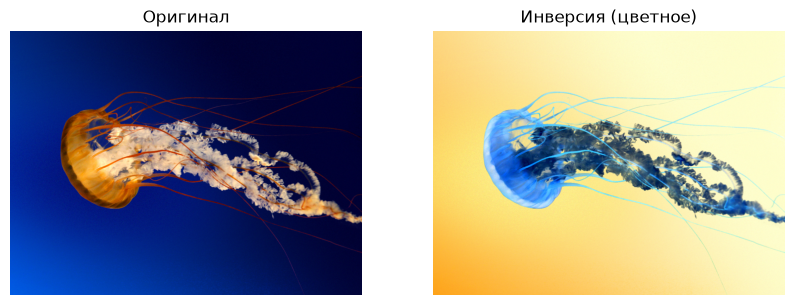

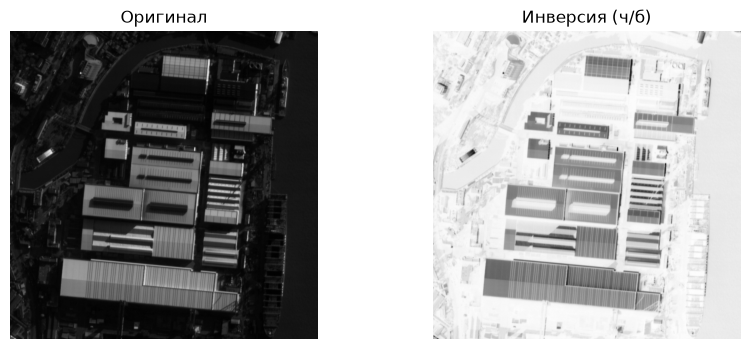

Бинаризация:


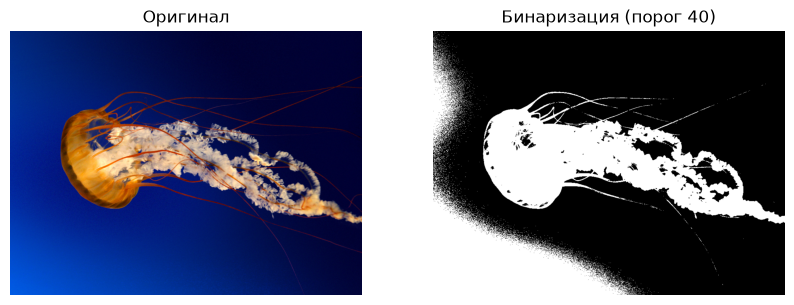

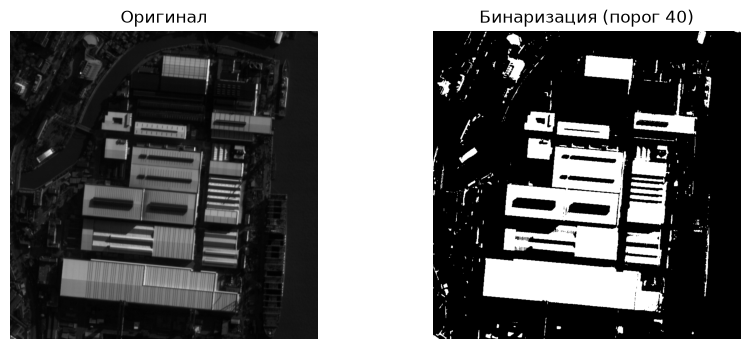

Разворот:


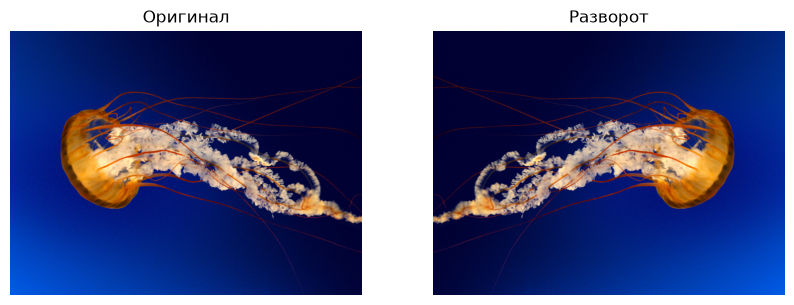

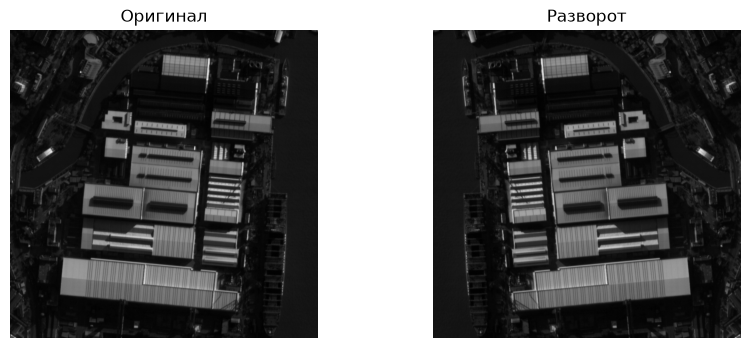

Облачность:
Цветное: 30.04%
Ч/б: 23.81%

Тест Rate Limiting (6 вызовов):
Вызов 1: True
Вызов 2: True
Вызов 3: True
Вызов 4: True
Вызов 5: True
Вызов 6: True

Журнал событий:
Всего событий: 134
Последние 10:
[125, '2026-10-19 17:59:17.913948', 'too_many_requests', None]
[126, '2026-10-19 17:59:18.692114', 'ping', 0.0017196999997395324]
[127, '2026-10-19 17:59:18.702416', 'too_many_requests', None]
[128, '2026-10-19 17:59:19.118368', 'ping', 0.0015679999996791594]
[129, '2026-10-19 17:59:19.129567', 'too_many_requests', None]
[130, '2026-10-19 17:59:21.675548', 'ping', 0.0017060999998648185]
[131, '2026-10-19 17:59:21.687106', 'too_many_requests', None]
[132, '2026-10-19 17:59:22.635969', 'ping', 0.0016960000002654851]
[133, '2026-10-19 17:59:22.645708', 'too_many_requests', None]
[134, '2026-10-19 17:59:22.909873', 'ping', 0.0019096000005447422]

Фильтрация по типу 'test_sum':
[6, '2026-10-19 16:50:42.845988', 'test_sum', 0.0012514999999666543]
[39, '2026-10-19 17:14:56.100518', 'test_s

In [1]:
import xmlrpc.client
import pickle
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
%matplotlib inline

def display_results(original, processed, title):
    plt.figure(figsize=(10, 4))
    plt.subplot(1, 2, 1)
    plt.title("Оригинал")
    cmap = 'gray' if len(original.shape) == 2 else None
    plt.imshow(original, cmap=cmap)
    plt.axis('off')
    plt.subplot(1, 2, 2)
    plt.title(title)
    cmap = 'gray' if len(processed.shape) == 2 else None
    plt.imshow(processed, cmap=cmap)
    plt.axis('off')
    plt.show()

server = xmlrpc.client.ServerProxy("http://localhost:8010", allow_none=True)
stats = xmlrpc.client.ServerProxy("http://localhost:8009", allow_none=True)

print("Тест базовых функций:")
print("Ping:", server.ping())
print("Now:", server.now())
print("Type:", server.show_type(2))
print("Sum:", server.test_sum(2, 3))
print("Pow:", server.test_pow(2, 3))

print("\nПроверка чёрного списка:")
test_cases = [
    ('Иванов', 'Иван', 'Иванович', '22.03.1989'),
    ('иванов', 'иван', 'иванович', '22.03.1989'),
    ('Иваноа', 'Иван', 'Иванович', '22.03.1989'),
    ('Сидоров', 'Пётр', 'Петрович', '01.01.1990')
]
for args in test_cases:
    print(args, "=>", server.black_list_check(*args))

print("\nОбработка изображений:")
img_color = np.array(Image.open('Jellyfish.jpg'))
img_mono = np.array(Image.open('11.bmp'))
pimg_color = xmlrpc.client.Binary(pickle.dumps(img_color))
pimg_mono = xmlrpc.client.Binary(pickle.dumps(img_mono))
threshold = 40

print("Инверсия:")
inv_color = pickle.loads(server.color_inversion(pimg_color).data)
inv_mono = pickle.loads(server.color_inversion(pimg_mono).data)
display_results(img_color, inv_color, "Инверсия (цветное)")
display_results(img_mono, inv_mono, "Инверсия (ч/б)")

print("Бинаризация:")
bw_color = pickle.loads(server.binarize_image(pimg_color, threshold).data)
bw_mono = pickle.loads(server.binarize_image(pimg_mono, threshold).data)
display_results(img_color, bw_color, f"Бинаризация (порог {threshold})")
display_results(img_mono, bw_mono, f"Бинаризация (порог {threshold})")

print("Разворот:")
flip_color = pickle.loads(server.flip_vertical(pimg_color).data)
flip_mono = pickle.loads(server.flip_vertical(pimg_mono).data)
display_results(img_color, flip_color, "Разворот")
display_results(img_mono, flip_mono, "Разворот")

print("Облачность:")
print(f"Цветное: {server.cloudiness_percent(pimg_color, threshold):.2f}%")
print(f"Ч/б: {server.cloudiness_percent(pimg_mono, threshold):.2f}%")

print("\nТест Rate Limiting (6 вызовов):")
for i in range(6):
    print(f"Вызов {i+1}:", server.ping())

print("\nЖурнал событий:")
events = stats.get_events('', '', '', '', '')
print(f"Всего событий: {len(events)}")
print("Последние 10:")
for e in events[-10:]:
    print(e)

print("\nФильтрация по типу 'test_sum':")
sum_events = stats.get_events('test_sum', '', '', '', '')
for e in sum_events:
    print(e)

print("\nОбщая статистика:")
stats_data = stats.get_stats()
print(f"Всего: {stats_data['count']}")
print(f"Средняя длительность: {stats_data['avg_duration']:.6f} сек")
print(f"Мин: {stats_data['min_duration']:.6f} сек")
print(f"Макс: {stats_data['max_duration']:.6f} сек")


In [2]:
import xmlrpc.client

# Подключиться к серверу статистики
stats = xmlrpc.client.ServerProxy("http://localhost:8009", allow_none=True)

# Получить все логи
events = stats.get_events('', '', '', '', '')
for e in events:
    print(e)


[1, '2026-10-19 16:42:47.551297', 'ping', 2.0467923000000496]
[2, '2026-10-19 16:42:53.679189', 'now', 2.0434806000000094]
[3, '2026-10-19 16:50:42.815463', 'ping', 0.0023569999999608626]
[4, '2026-10-19 16:50:42.825531', 'now', 0.0012966000000460554]
[5, '2026-10-19 16:50:42.836011', 'show_type', 0.0016061000000036074]
[6, '2026-10-19 16:50:42.845988', 'test_sum', 0.0012514999999666543]
[7, '2026-10-19 16:50:42.855972', 'test_pow', 0.0016880000000583095]
[8, '2026-10-19 16:50:42.864889', 'too_many_requests', None]
[9, '2026-10-19 16:50:47.886838', 'black_list_check', 0.06657829999994647]
[10, '2026-10-19 16:50:47.899315', 'black_list_check', 0.004264699999907862]
[11, '2026-10-19 16:50:47.910956', 'black_list_check', 0.0039859000000888045]
[12, '2026-10-19 16:50:47.923480', 'black_list_check', 0.003847800000016832]
[13, '2026-10-19 16:50:48.265561', 'color_inversion', 0.22692830000005415]
[14, '2026-10-19 16:50:48.441656', 'too_many_requests', None]
[15, '2026-10-19 16:50:52.881051', 